- **Name:** Amir Khan  
- **Student ID:** 023-24-0166
- **Section:** F
- **GitHub:** https://github.com/Amir-Khan11  
- **Kaggle:** https://www.kaggle.com/amirkhan123123
- **Dataset:** House Prices — Advanced Regression Techniques (Ames, Iowa housing data)  
- **Dataset Source:** Kaggle — https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

# Lab 5 — Linear Regression: Predicting House Prices

Machine Learning Lab · BS Computer Science, 5th Semester

**How to run this notebook (Google Colab):**
1. Download `train.csv`, `test.csv` and `sample_submission.csv` from the competition's *Data* tab on Kaggle.
2. Runtime → Run all. If asked, upload the three files (or put them in `/content` or your Drive folder first).
3. The notebook saves `submission.csv` in Section 13 — upload that on Kaggle's *Submit Predictions* page.
4. Fill in your name/ID block above and the Kaggle score/rank in Section 13.4, then save as `lab5_<yourname>_house_price.ipynb`.

In [1]:
# Setup: imports and global settings
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RANDOM_STATE = 42  # makes the train/test split (and every result) reproducible

---
## 🔷 Part 1 — Dataset, Problem & Feature/Target Identification
*(Lab Manual — Tasks 1–3)*

---
## 1. Problem Definition

> **Task 3 (Part 1):** In 1–2 sentences, state why this is a regression problem rather than a classification problem, and what that changes about how you'll evaluate the model later.

We're trying to predict `SalePrice` (in US dollars) for houses in Ames, Iowa, using Multiple Linear Regression. `train.csv` has 1,460 houses with known prices, and `test.csv` has 1,459 houses we need to predict prices for.

This is a regression problem, not classification, because `SalePrice` is a continuous dollar amount, not a category. So instead of accuracy, we use MAE, MSE, RMSE and R² to see how close our predictions are, and we look at the residuals (actual − predicted) too.

Kaggle actually scores submissions using RMSE on the *log* of the price. We report the normal dollar-based metrics as the lab asks, but we also compute the log-based score in Section 13 for comparison.


---
## 2. Dataset Exploration

> **Task 1 (Part 1):** Load the dataset and briefly inspect it (shape, dtypes, first few rows, summary statistics).

We load the three competition files and take a look at them. All the exploring below uses `train.csv`, since it's the only file with the target. `test.csv` is only checked for structure and missing values — we don't use it to make any modeling decisions.


### 2.1 Loading the data

In [2]:
DATA_FILES = ["train.csv", "test.csv", "sample_submission.csv"]
SEARCH_DIRS = [".", "/content", "/content/drive/MyDrive", "data",
               "/kaggle/input/house-prices-advanced-regression-techniques"]

def locate_data():
    for folder in SEARCH_DIRS:
        if all(os.path.exists(os.path.join(folder, f)) for f in DATA_FILES):
            return folder
    return None

DATA_DIR = locate_data()
if DATA_DIR is None:                      # not found -> ask for an upload (Colab only)
    try:
        from google.colab import files
        print("Please upload train.csv, test.csv and sample_submission.csv")
        files.upload()
        DATA_DIR = locate_data()
    except ImportError:
        pass
if DATA_DIR is None:
    raise FileNotFoundError("Could not find train.csv, test.csv and sample_submission.csv. "
                            "Download them from the Kaggle competition's Data tab and upload them to Colab.")

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

overview = pd.DataFrame({
    "File": DATA_FILES,
    "Rows": [d.shape[0] for d in (train, test, sample_sub)],
    "Columns": [d.shape[1] for d in (train, test, sample_sub)],
    "Contains SalePrice?": ["SalePrice" in d.columns for d in (train, test, sample_sub)],
})
display(overview)

,File,Rows,Columns,Contains SalePrice?
0,train.csv,1460,81,True
1,test.csv,1459,80,False
2,sample_submission.csv,1459,2,True


**Interpretation.** `train.csv` has 1,460 houses and 81 columns (`Id`, 79 features, and `SalePrice`). `test.csv` has 1,459 houses with the same columns minus `SalePrice`. `sample_submission.csv` only has 2 columns, which tells us our final submission needs one prediction per house. Since `test.csv` has no prices, we'll hold out part of `train.csv` to check our own model.

### 2.2 First rows of the training data

In [3]:
display(train.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,...,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,...,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,...,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**Interpretation.** Each row is one house, and the last column is `SalePrice` — for example, the first house sold for 208,500 USD. The data mixes numbers (`LotArea`, `YearBuilt`), text categories (`MSZoning`, `Neighborhood`), and some missing values, so it'll need cleaning and encoding before we can model it. With 81 columns, it's also pretty clear we should pick a smaller set of features instead of using everything.

### 2.3 Summary statistics (all numerical columns)

In [4]:
full_describe = train.describe().T
display(full_describe)

,count,mean,std,min,25%,50%,75%,max
Id,"1,460.00",730.50,421.61,1.00,365.75,730.50,"1,095.25","1,460.00"
MSSubClass,"1,460.00",56.90,42.30,20.00,20.00,50.00,70.00,190.00
LotFrontage,"1,201.00",70.05,24.28,21.00,59.00,69.00,80.00,313.00
LotArea,"1,460.00","10,516.83","9,981.26","1,300.00","7,553.50","9,478.50","11,601.50","215,245.00"
OverallQual,"1,460.00",6.10,1.38,1.00,5.00,6.00,7.00,10.00
OverallCond,"1,460.00",5.58,1.11,1.00,5.00,5.00,6.00,9.00
YearBuilt,"1,460.00","1,971.27",30.20,"1,872.00","1,954.00","1,973.00","2,000.00","2,010.00"
YearRemodAdd,"1,460.00","1,984.87",20.65,"1,950.00","1,967.00","1,994.00","2,004.00","2,010.00"
MasVnrArea,"1,452.00",103.69,181.07,0.00,0.00,0.00,166.00,"1,600.00"
BsmtFinSF1,"1,460.00",443.64,456.10,0.00,0.00,383.50,712.25,"5,644.00"


**Interpretation.** `train.describe()` gives stats for all 38 numeric columns. Most have the full 1,460 values, except `LotFrontage`, `MasVnrArea` and `GarageYrBlt`, which have some missing data. The columns are on very different scales too — `OverallQual` is 1–10, while `LotArea` is in the thousands — which is one reason we pick a small, well-understood set of features instead of using all 38 (plus the 43 text columns) directly.

### 2.4 Data types

In [5]:
dtype_counts = train.dtypes.astype(str).value_counts().rename_axis("Data type").reset_index(name="Number of columns")
display(dtype_counts)

,Data type,Number of columns
0,str,43
1,int64,35
2,float64,3


**Interpretation.** 38 of the 81 columns are numeric, and 43 are text. Since Linear Regression only works with numbers, any text column we use will need to be converted first.

### 2.5 Missing values

In [6]:
missing_pct = (train.isna().mean() * 100).sort_values(ascending=False)
top_missing = missing_pct[missing_pct > 0].head(8).rename("Missing (%)").rename_axis("Column").reset_index()
display(top_missing)
print(f"Columns with at least one missing value: {(train.isna().sum() > 0).sum()} of {train.shape[1]}")

,Column,Missing (%)
0,PoolQC,99.52
1,MiscFeature,96.30
2,Alley,93.77
3,Fence,80.75
4,MasVnrType,59.73
5,FireplaceQu,47.26
6,LotFrontage,17.74
7,GarageQual,5.55


Columns with at least one missing value: 19 of 81


**Interpretation.** A few columns are almost entirely empty — `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%) and `Fence` (80.8%) — and 19 of the 81 columns have at least one missing value. For most of these, missing just means the house doesn't have that feature (no pool, no alley), not that data was lost. That's another reason to stick with a smaller set of reliable features instead of all 79.

### 2.6 Duplicate values

In [7]:
duplicates = pd.DataFrame({
    "Check": ["Fully duplicated rows in train.csv", "Duplicated Id values in train.csv", "Duplicated Id values in test.csv"],
    "Count": [int(train.duplicated().sum()), int(train["Id"].duplicated().sum()), int(test["Id"].duplicated().sum())],
})
display(duplicates)

,Check,Count
0,Fully duplicated rows in train.csv,0
1,Duplicated Id values in train.csv,0
2,Duplicated Id values in test.csv,0


**Interpretation.** No duplicate rows and no repeated `Id`s in either file, so every house shows up exactly once. No cleanup needed here.

### 2.7 The target variable: SalePrice

In [8]:
TARGET = "SalePrice"
target_stats = train[TARGET].describe().to_frame("SalePrice (USD)")
target_stats.loc["skewness"] = train[TARGET].skew()
display(target_stats)

,SalePrice (USD)
count,"1,460.00"
mean,"180,921.20"
std,"79,442.50"
min,"34,900.00"
25%,"129,975.00"
50%,"163,000.00"
75%,"214,000.00"
max,"755,000.00"
skewness,1.88


**Interpretation.** The average price is about 180,921 USD, but the median is lower at 163,000 USD, and the max (755,000 USD) is way further from the median than the min (34,900 USD) is. The skewness of 1.88 confirms there's a long tail of expensive houses, which could make the model's errors bigger for those cases.

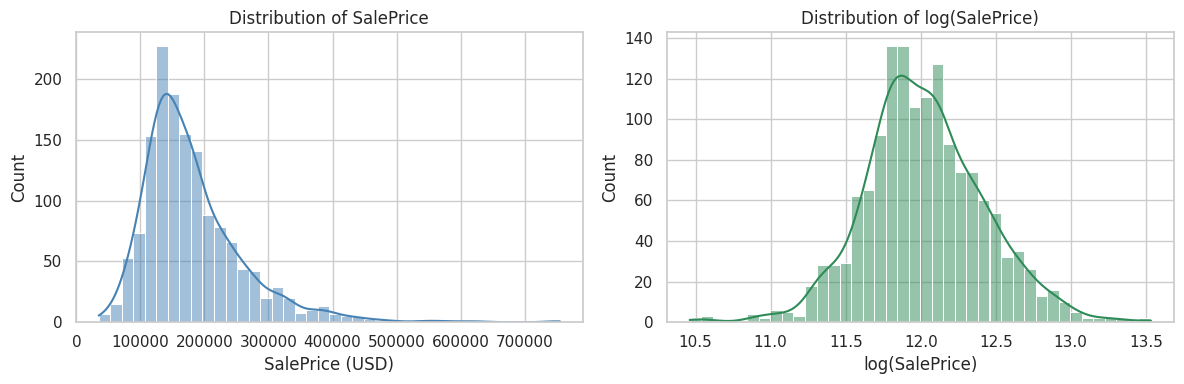

Skewness of SalePrice: 1.88   |   Skewness of log(SalePrice): 0.12


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train[TARGET], bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("SalePrice (USD)")
sns.histplot(np.log(train[TARGET]), bins=40, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("Distribution of log(SalePrice)")
axes[1].set_xlabel("log(SalePrice)")
plt.tight_layout()
plt.show()
print(f"Skewness of SalePrice: {train[TARGET].skew():.2f}   |   Skewness of log(SalePrice): {np.log(train[TARGET]).skew():.2f}")

**Interpretation.** Most houses sell between 100,000–250,000 USD, with a long tail up to 755,000 USD. Taking the log of `SalePrice` makes the distribution much more symmetric (skewness drops from 1.88 to 0.12). Kaggle actually scores on the log scale, but we're modeling the raw price as the lab asks, so we should expect bigger errors on the expensive houses.

### 2.8 Candidate features

The lab manual asks for a manageable set of 10–12 features that mix numbers and categories. We picked 12 features we'd expect to matter for price (more on why in Section 3) and look at them here.

In [10]:
NUM_FEATURES = ["GrLivArea", "LotArea", "OverallQual", "YearBuilt",
                "TotalBsmtSF", "GarageCars", "FullBath", "Fireplaces"]
CAT_FEATURES = ["Neighborhood", "HouseStyle", "KitchenQual", "CentralAir"]

display(train[NUM_FEATURES].describe().T)

,count,mean,std,min,25%,50%,75%,max
GrLivArea,"1,460.00","1,515.46",525.48,334.00,"1,129.50","1,464.00","1,776.75","5,642.00"
LotArea,"1,460.00","10,516.83","9,981.26","1,300.00","7,553.50","9,478.50","11,601.50","215,245.00"
OverallQual,"1,460.00",6.10,1.38,1.00,5.00,6.00,7.00,10.00
YearBuilt,"1,460.00","1,971.27",30.20,"1,872.00","1,954.00","1,973.00","2,000.00","2,010.00"
TotalBsmtSF,"1,460.00","1,057.43",438.71,0.00,795.75,991.50,"1,298.25","6,110.00"
GarageCars,"1,460.00",1.77,0.75,0.00,1.00,2.00,2.00,4.00
FullBath,"1,460.00",1.57,0.55,0.00,1.00,2.00,2.00,3.00
Fireplaces,"1,460.00",0.61,0.64,0.00,0.00,1.00,1.00,3.00


**Interpretation.** These features are on very different scales — `OverallQual` goes 1–10, `GarageCars` goes 0–4, but `GrLivArea` goes up to 5,642 sq ft and `LotArea` up to 215,245 sq ft. The averages look reasonable for Ames homes (about 1,515 sq ft, built around 1971, room for 2 cars). None of them have missing values in `train.csv`. Because the scales are so different, we can't compare raw coefficients directly later.

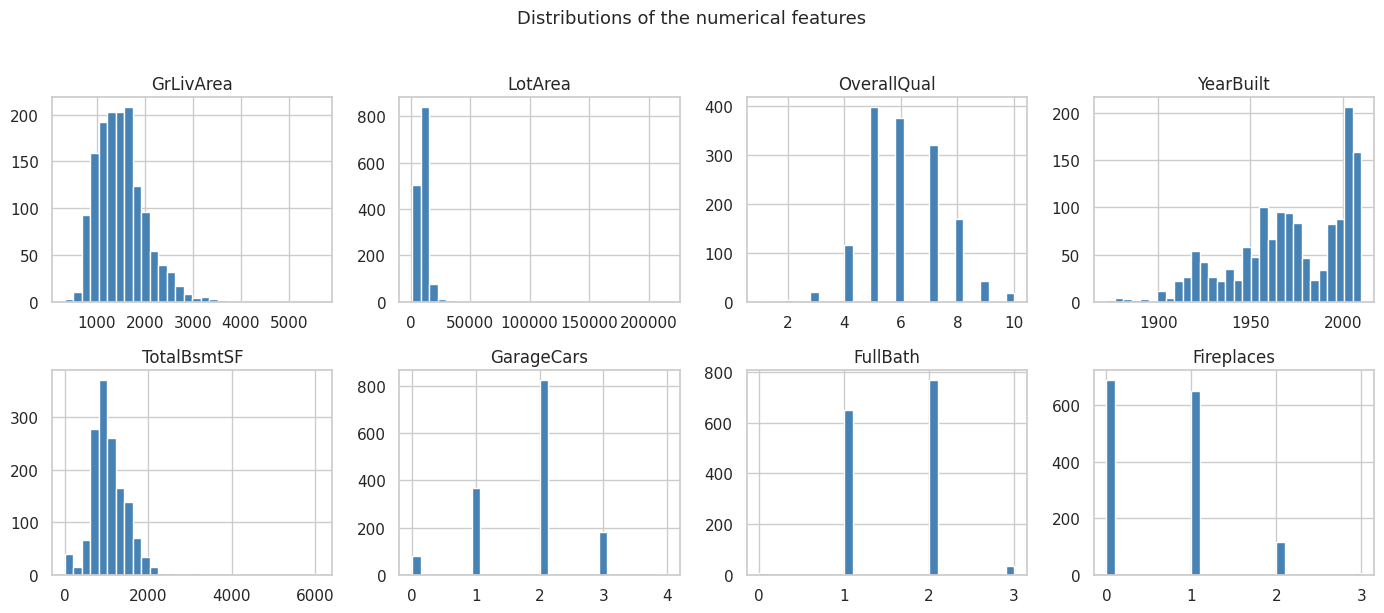

In [11]:
train[NUM_FEATURES].hist(bins=30, figsize=(14, 6), color="steelblue", edgecolor="white", layout=(2, 4))
plt.suptitle("Distributions of the numerical features", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

**Interpretation.** `GrLivArea`, `TotalBsmtSF` and `LotArea` are right-skewed with a few very large values. `OverallQual`, `GarageCars`, `FullBath` and `Fireplaces` only take a few whole-number values, and `YearBuilt` peaks around 2000–2010. Nothing looks constant, so all of these features could carry some signal.

In [12]:
cat_summary = pd.DataFrame({
    "Feature": CAT_FEATURES,
    "Unique categories": [train[c].nunique() for c in CAT_FEATURES],
    "Most common category": [train[c].mode()[0] for c in CAT_FEATURES],
    "Share of houses in it (%)": [train[c].value_counts(normalize=True).iloc[0] * 100 for c in CAT_FEATURES],
})
display(cat_summary)

,Feature,Unique categories,Most common category,Share of houses in it (%)
0,Neighborhood,25,NAmes,15.41
1,HouseStyle,8,1Story,49.73
2,KitchenQual,4,TA,50.34
3,CentralAir,2,Y,93.49


**Interpretation.** `Neighborhood` has 25 categories (`NAmes` is the biggest at 15.4%), `HouseStyle` has 8 (about half are `1Story`), `KitchenQual` has 4 (`TA` is most common at 50.3%), and `CentralAir` is `Y` for 93.5% of houses. The multi-category columns will turn into a lot of dummy columns later.

### 2.9 Relationships with SalePrice

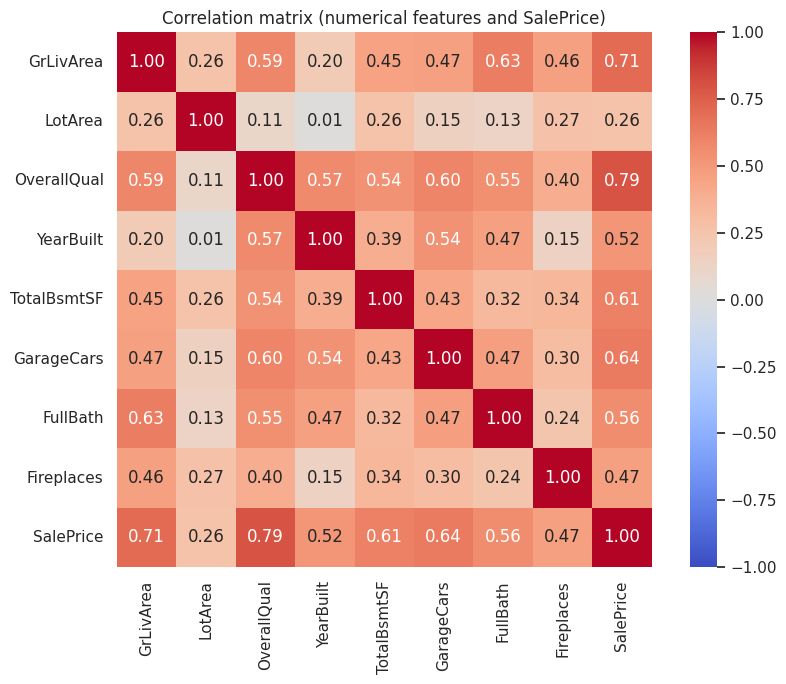

In [13]:
corr = train[NUM_FEATURES + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (numerical features and SalePrice)")
plt.tight_layout()
plt.show()

**Interpretation.** `OverallQual` (0.79) and `GrLivArea` (0.71) have the strongest correlation with `SalePrice`, followed by `GarageCars` (0.64), `TotalBsmtSF` (0.61), `FullBath` (0.56), `YearBuilt` (0.52) and `Fireplaces` (0.47). `LotArea` is weaker (0.26). All the correlations are positive, which makes sense. Some features are also correlated with each other (like `GrLivArea` and `FullBath` at 0.63), so their individual coefficients later might be a bit harder to read on their own.

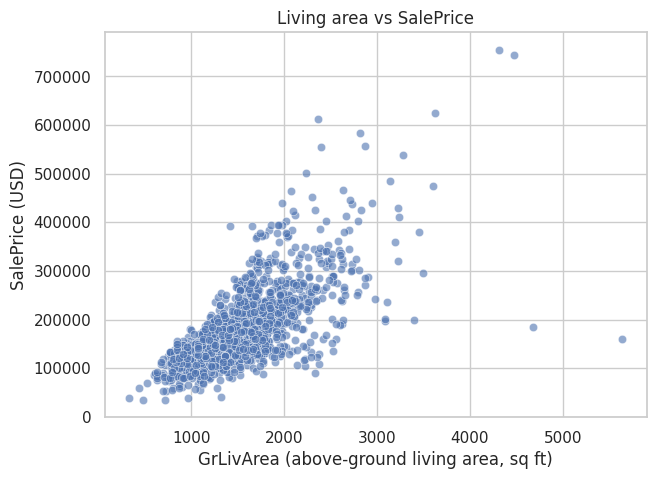

In [14]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=train, x="GrLivArea", y=TARGET, alpha=0.6)
plt.title("Living area vs SalePrice")
plt.xlabel("GrLivArea (above-ground living area, sq ft)")
plt.ylabel("SalePrice (USD)")
plt.show()

**Interpretation.** Price rises roughly in a straight line as living area increases, which supports using a linear model. A few outliers stand out though — two houses over 4,600 sq ft sold for only around 160,000–185,000 USD, while two around 4,300–4,500 sq ft sold for over 700,000 USD. Points like these could pull the fitted line off and cause bigger errors.

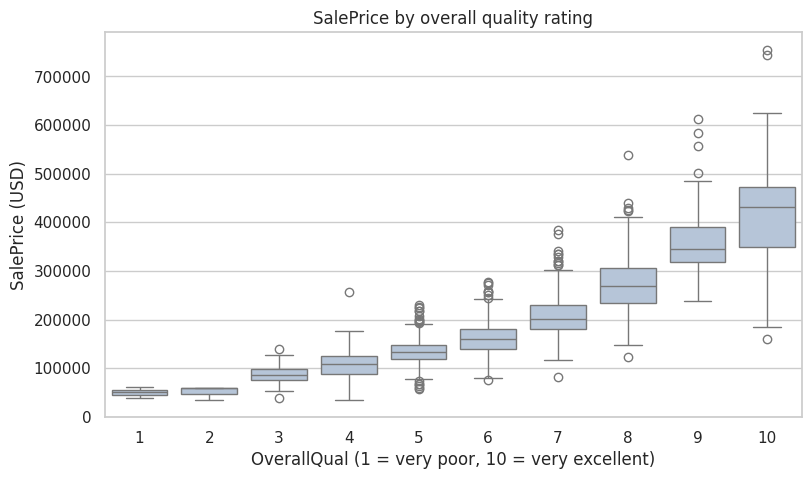

In [15]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=train, x="OverallQual", y=TARGET, color="lightsteelblue")
plt.title("SalePrice by overall quality rating")
plt.xlabel("OverallQual (1 = very poor, 10 = very excellent)")
plt.ylabel("SalePrice (USD)")
plt.show()

**Interpretation.** Median price rises steadily with quality, from about 50,000 USD at quality 1 to about 430,000 USD at quality 10. The jump gets bigger at higher quality levels, so the relationship isn't perfectly straight — this probably means the model will underpredict the highest-quality houses a bit.

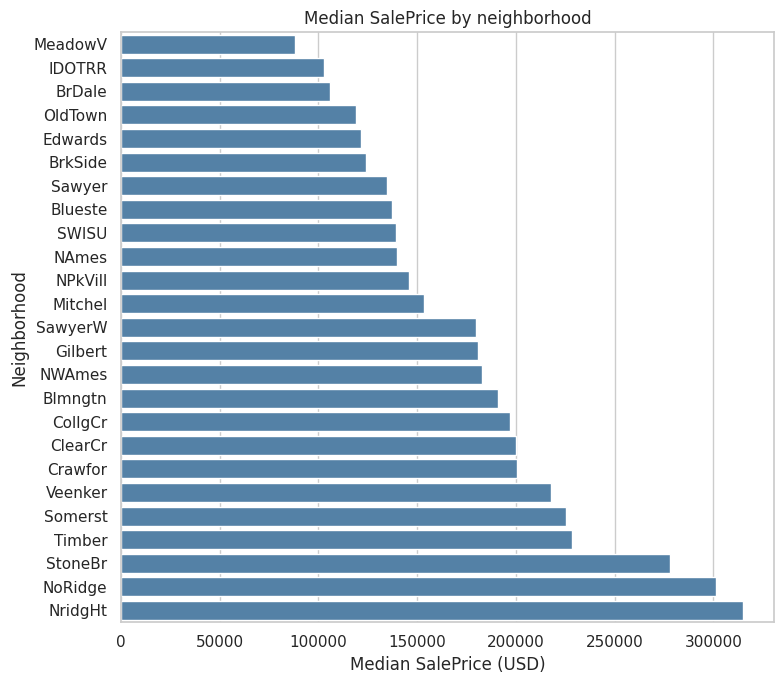

In [16]:
median_by_nbhd = train.groupby("Neighborhood")[TARGET].median().sort_values()
plt.figure(figsize=(8, 7))
sns.barplot(x=median_by_nbhd.values, y=median_by_nbhd.index, color="steelblue")
plt.title("Median SalePrice by neighborhood")
plt.xlabel("Median SalePrice (USD)")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

**Interpretation.** Location clearly matters — median prices go from under 90,000 USD in `MeadowV` to over 300,000 USD in `NridgHt`, with `NoRidge` and `StoneBr` also near the top. That's a good reason to include `Neighborhood` as a feature.

### 2.10 Missing values in the chosen features (train vs test)

In [17]:
ALL_FEATURES = NUM_FEATURES + CAT_FEATURES
missing_check = pd.DataFrame({
    "Missing in train.csv": train[ALL_FEATURES].isna().sum(),
    "Missing in test.csv": test[ALL_FEATURES].isna().sum(),
})
display(missing_check)

,Missing in train.csv,Missing in test.csv
GrLivArea,0,0
LotArea,0,0
OverallQual,0,0
YearBuilt,0,0
TotalBsmtSF,0,1
GarageCars,0,1
FullBath,0,0
Fireplaces,0,0
Neighborhood,0,0
HouseStyle,0,0


**Interpretation.** None of our 12 chosen features are missing in `train.csv`, but `test.csv` has one missing value each in `TotalBsmtSF`, `GarageCars` and `KitchenQual`. We fill these in later (Section 13.1) using values from the training data only.

---
## 3. Feature and Target Identification

> **Task 2 (Part 1):** Identify the dependent variable and list the independent variables, split explicitly into numerical features and categorical features.


In [18]:
feature_table = pd.DataFrame([
    ("GrLivArea",   "Numerical",   "Above-ground living area (sq ft)",           "Size of the living space is the most obvious price driver"),
    ("LotArea",     "Numerical",   "Lot size (sq ft)",                           "Bigger plots of land usually cost more"),
    ("OverallQual", "Numerical",   "Overall material and finish quality (1-10)", "Quality is expected to be a strong price driver"),
    ("YearBuilt",   "Numerical",   "Original construction year",                 "Newer houses tend to sell for more"),
    ("TotalBsmtSF", "Numerical",   "Total basement area (sq ft)",                "Extra usable space adds value"),
    ("GarageCars",  "Numerical",   "Garage capacity (number of cars)",           "Garage capacity is a common buyer requirement"),
    ("FullBath",    "Numerical",   "Number of full bathrooms above ground",      "Suggested by the lab manual (bathrooms)"),
    ("Fireplaces",  "Numerical",   "Number of fireplaces",                       "A comfort feature often linked to higher-end homes"),
    ("Neighborhood","Categorical", "Location inside Ames (25 categories)",       "Location strongly affects price (nominal, no order)"),
    ("HouseStyle",  "Categorical", "Style of dwelling (8 categories)",           "Suggested by the lab manual (nominal, no order)"),
    ("KitchenQual", "Categorical", "Kitchen quality: Po < Fa < TA < Gd < Ex",    "Suggested by the lab manual (ordinal, natural order)"),
    ("CentralAir",  "Categorical", "Central air conditioning: Y / N",            "Simple yes/no comfort feature (binary)"),
], columns=["Feature", "Type", "Meaning", "Why we chose it"])
display(feature_table)

,Feature,Type,Meaning,Why we chose it
0,GrLivArea,Numerical,Above-ground living area (sq ft),Size of the living space is the most obvious price driver
1,LotArea,Numerical,Lot size (sq ft),Bigger plots of land usually cost more
2,OverallQual,Numerical,Overall material and finish quality (1-10),Quality is expected to be a strong price driver
3,YearBuilt,Numerical,Original construction year,Newer houses tend to sell for more
4,TotalBsmtSF,Numerical,Total basement area (sq ft),Extra usable space adds value
5,GarageCars,Numerical,Garage capacity (number of cars),Garage capacity is a common buyer requirement
6,FullBath,Numerical,Number of full bathrooms above ground,Suggested by the lab manual (bathrooms)
7,Fireplaces,Numerical,Number of fireplaces,A comfort feature often linked to higher-end homes
8,Neighborhood,Categorical,Location inside Ames (25 categories),"Location strongly affects price (nominal, no order)"
9,HouseStyle,Categorical,Style of dwelling (8 categories),"Suggested by the lab manual (nominal, no order)"


**Interpretation.** We picked 12 features — 8 numerical and 4 categorical — that cover most of the examples the lab manual suggests (living area, quality, basement, garage, year built, bathrooms, neighborhood, house style, kitchen quality), plus `LotArea`, `Fireplaces` and `CentralAir`. We didn't use all 79 columns because many are mostly empty or overlap with the ones we already picked.

In [19]:
ID_COLUMN = "Id"

print(f"Target (dependent variable): {TARGET}")
print(f"ID column (not a feature)  : {ID_COLUMN}")
print(f"\nNumerical features  ({len(NUM_FEATURES)}): {NUM_FEATURES}")
print(f"Categorical features ({len(CAT_FEATURES)}): {CAT_FEATURES}")
print(f"Total features       : {len(NUM_FEATURES) + len(CAT_FEATURES)}")

assert TARGET not in NUM_FEATURES + CAT_FEATURES, "Target leakage: SalePrice must not be a feature"
assert ID_COLUMN not in NUM_FEATURES + CAT_FEATURES, "Id is an identifier, not a feature"
print("\nChecks passed: the target and the Id column are not used as features.")

Target (dependent variable): SalePrice
ID column (not a feature)  : Id

Numerical features  (8): ['GrLivArea', 'LotArea', 'OverallQual', 'YearBuilt', 'TotalBsmtSF', 'GarageCars', 'FullBath', 'Fireplaces']
Categorical features (4): ['Neighborhood', 'HouseStyle', 'KitchenQual', 'CentralAir']
Total features       : 12

Checks passed: the target and the Id column are not used as features.


**Interpretation.** `SalePrice` is our target, and the other 12 columns are our features (8 numerical, 4 categorical). `Id` is just an identifier, not a feature. The checks confirm `SalePrice` isn't accidentally included as a feature, so there's no data leakage.

---
## 🔷 Part 2 — Data Preparation & Train/Test Split
*(Lab Manual — Tasks 4–6)*

---
## 4. Data Preparation

> **Task 4 (Part 2):** Prepare X (features) and y (price) for modeling — encode every categorical column into numeric form, and briefly justify the choice of encoding method for each type of column.

`LinearRegression` needs fully numeric input with no missing values, so we need to encode the categorical columns first. How we encode each one depends on what kind of category it is:


In [20]:
encoding_plan = pd.DataFrame([
    ("CentralAir",              "Binary (Y / N)",        "Map to 1 / 0",                 "Only two categories, so one 0/1 column keeps all the information"),
    ("KitchenQual",             "Ordinal (has an order)", "Ordinal map: Po=1 ... Ex=5",   "The order Po < Fa < TA < Gd < Ex is meaningful; a single number preserves it and adds only one column"),
    ("Neighborhood, HouseStyle","Nominal (no order)",    "One-hot (get_dummies)",        "Numbers such as 1, 2, 3 would invent a false order; one-hot gives each category its own 0/1 column"),
], columns=["Column(s)", "Kind of variable", "Encoding", "Justification"])
display(encoding_plan)

,Column(s),Kind of variable,Encoding,Justification
0,CentralAir,Binary (Y / N),Map to 1 / 0,"Only two categories, so one 0/1 column keeps all the information"
1,KitchenQual,Ordinal (has an order),Ordinal map: Po=1 ... Ex=5,The order Po < Fa < TA < Gd < Ex is meaningful; a single number preserves it and adds only one column
2,"Neighborhood, HouseStyle",Nominal (no order),One-hot (get_dummies),"Numbers such as 1, 2, 3 would invent a false order; one-hot gives each category its own 0/1 column"


**Interpretation.** A binary column like `CentralAir` only needs one 0/1 column. `KitchenQual` has a natural order (Poor to Excellent), so we map it to numbers 1–5 to keep that order. `Neighborhood` and `HouseStyle` have no natural order, so we one-hot encode them instead — using numbers like 1, 2, 3 would wrongly imply an order that doesn't exist. We use `drop_first=True` to drop one category per column as the baseline, which avoids redundant columns.

In [21]:
KITCHEN_MAP = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
AIR_MAP = {"N": 0, "Y": 1}
ONE_HOT_COLS = ["Neighborhood", "HouseStyle"]

def encode_features(df):
    # Select the chosen features and convert every categorical column to numbers.
    # The same function is reused later for test.csv, so both files are encoded identically.
    X_enc = df[NUM_FEATURES + CAT_FEATURES].copy()
    X_enc["CentralAir"] = X_enc["CentralAir"].map(AIR_MAP)
    X_enc["KitchenQual"] = X_enc["KitchenQual"].map(KITCHEN_MAP)
    # drop_first=True removes one redundant dummy per column (the "baseline" category)
    return pd.get_dummies(X_enc, columns=ONE_HOT_COLS, drop_first=True, dtype=int)

X = encode_features(train)
y = train[TARGET]

display(X.head())
print(f"X shape: {X.shape}   |   y shape: {y.shape}")

,GrLivArea,LotArea,OverallQual,YearBuilt,TotalBsmtSF,GarageCars,FullBath,Fireplaces,KitchenQual,CentralAir,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,...,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl
0,1710,8450,7,2003,856,2,2,0,4,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,1262,9600,6,1976,1262,2,2,1,3,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0
2,1786,11250,7,2001,920,2,2,1,4,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,1717,9550,7,1915,756,3,1,1,4,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,2198,14260,8,2000,1145,3,2,1,4,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


X shape: (1460, 41)   |   y shape: (1460,)


**Interpretation.** `X` is now fully numeric — the 8 original numeric features, `CentralAir` as 0/1, `KitchenQual` as 1–5, and dummy columns for each `Neighborhood`/`HouseStyle` category except the baseline. `X` has 1,460 rows and 41 columns, matching `y`'s 1,460 prices.

In [22]:
n_onehot = {c: sum(col.startswith(c + "_") for col in X.columns) for c in ONE_HOT_COLS}
prep_checks = pd.DataFrame({
    "Check": ["All columns in X are numeric", "Missing values in X", "Missing values in y",
              "Total columns in X", "  = numerical features + CentralAir + KitchenQual",
              "  + one-hot columns for Neighborhood", "  + one-hot columns for HouseStyle"],
    "Result": [bool(X.shape[1] == X.select_dtypes(include="number").shape[1]),
               int(X.isna().sum().sum()), int(y.isna().sum()),
               X.shape[1], len(NUM_FEATURES) + 2, n_onehot["Neighborhood"], n_onehot["HouseStyle"]],
})
display(prep_checks)

,Check,Result
0,All columns in X are numeric,True
1,Missing values in X,0
2,Missing values in y,0
3,Total columns in X,41
4,= numerical features + CentralAir + KitchenQual,10
5,+ one-hot columns for Neighborhood,24
6,+ one-hot columns for HouseStyle,7


> **Task 5 (Part 2):** Confirm X is fully numeric with no missing values.

**Interpretation.** All checks pass — `X` is fully numeric with no missing values, and the column count adds up correctly (10 base columns + 24 `Neighborhood` dummies + 7 `HouseStyle` dummies = 41). `X` is ready for `LinearRegression`.

---
## 5. Train/Test Split

> **Task 6 (Part 2):** Split X and y into training and test sets (e.g. an 80/20 split) and report the resulting shapes.

We hold out 20% of the houses as a test set before training anything, so we can check the model on houses it hasn't seen.


In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Set": ["Training", "Testing"],
    "Rows (houses)": [X_train.shape[0], X_test.shape[0]],
    "Features": [X_train.shape[1], X_test.shape[1]],
    "Share of data (%)": [100 * len(X_train) / len(X), 100 * len(X_test) / len(X)],
    "Mean SalePrice (USD)": [y_train.mean(), y_test.mean()],
    "Std. dev. of SalePrice (USD)": [y_train.std(), y_test.std()],
})
display(split_summary)
print(f"X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}  y_test : {y_test.shape}")

,Set,Rows (houses),Features,Share of data (%),Mean SalePrice (USD),Std. dev. of SalePrice (USD)
0,Training,1168,41,80.00,"181,441.54","77,263.58"
1,Testing,292,41,20.00,"178,839.81","87,730.75"


X_train: (1168, 41)  y_train: (1168,)
X_test : (292, 41)  y_test : (292,)


**Interpretation.** The 80/20 split gives us 1,168 training houses and 292 test houses, both with the same 41 features. Average prices are similar in both sets (181,442 vs 178,840 USD), so the split looks representative. The test set has a slightly bigger price spread, which is worth keeping in mind when we compare train/test scores later in Section 11.

---
## 🔷 Part 3 — Linear Regression & Predictions
*(Lab Manual — Tasks 7–8)*

---
## 6. Linear Regression Model

> **Task 7 (Part 3):** Train a LinearRegression model on the training data.

Linear Regression predicts price using an intercept plus a weight (coefficient) for each feature. We use scikit-learn's default `LinearRegression`, which doesn't need any tuning.


In [24]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained:", model)
print("Number of training houses :", len(X_train))
print("Number of input features  :", model.n_features_in_)
print("Number of coefficients    :", len(model.coef_))

Model trained: LinearRegression()
Number of training houses : 1168
Number of input features  : 41
Number of coefficients    : 41


**Interpretation.** The model trained on the 1,168 training houses using all 41 features, learning 41 coefficients plus one intercept. It hasn't seen the 292 test houses yet — those are kept aside to check the model fairly.

---
## 7. Predictions

> **Task 8 (Part 3):** Generate predicted prices on the test set, and display a small table comparing actual vs. predicted price for 10 test houses.


In [25]:
y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)   # needed later for the training-vs-testing comparison

comparison = pd.DataFrame({
    "Id": train.loc[X_test.index, "Id"],
    "Actual Price (USD)": y_test,
    "Predicted Price (USD)": y_pred_test,
})
comparison["Error (USD)"] = comparison["Actual Price (USD)"] - comparison["Predicted Price (USD)"]
comparison["Abs. Error (% of actual)"] = 100 * comparison["Error (USD)"].abs() / comparison["Actual Price (USD)"]

sample10 = comparison.sample(10, random_state=RANDOM_STATE).reset_index(drop=True)
display(sample10.style.hide(axis="index").format({
    "Actual Price (USD)": "{:,.0f}", "Predicted Price (USD)": "{:,.0f}",
    "Error (USD)": "{:+,.0f}", "Abs. Error (% of actual)": "{:.1f}%"}))

Id,Actual Price (USD),Predicted Price (USD),Error (USD),Abs. Error (% of actual)
417,"149,500","152,782","-3,282",2.2%
775,"395,000","317,427","+77,573",19.6%
1133,"117,500","137,553","-20,053",17.1%
240,"113,000","136,872","-23,872",21.1%
1093,"136,500","160,546","-24,046",17.6%
1273,"137,000","116,620","+20,380",14.9%
1433,"64,500","85,890","-21,390",33.2%
1217,"112,000","173,650","-61,650",55.0%
888,"135,500","118,750","+16,750",12.4%
837,"153,500","150,325","+3,175",2.1%


**Interpretation.** Comparing actual vs predicted prices for 10 random test houses, two predictions were very close (about 2% off), six were off by 12–21%, and two were noticeably worse — one overpredicted by about 61,650 USD and one underpredicted by about 77,573 USD. So the model gets the general price range right but can be pretty off on individual, unusual houses.

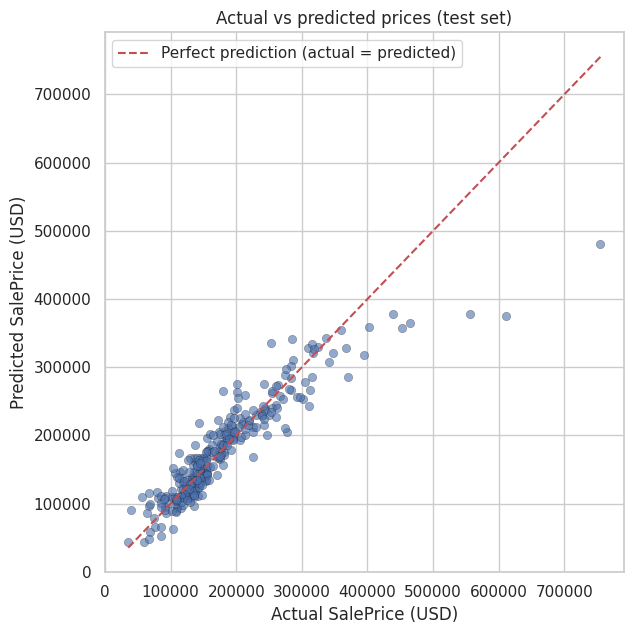

In [26]:
plt.figure(figsize=(6.5, 6.5))
plt.scatter(y_test, y_pred_test, alpha=0.6, edgecolor="k", linewidth=0.3)
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction (actual = predicted)")
plt.xlabel("Actual SalePrice (USD)")
plt.ylabel("Predicted SalePrice (USD)")
plt.title("Actual vs predicted prices (test set)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation.** Each point is one test house — a perfect model would put every point on the red line. Points follow the line closely below about 300,000 USD, but for the most expensive houses (above ~400,000 USD) the points fall below the line, meaning the model underpredicts them. The 755,000 USD house, for example, was predicted at only about 480,000 USD. The model does well for typical houses but struggles at the high end.

---
## 🔷 Part 4 — Coefficients & Intercept
*(Lab Manual — Tasks 9–10)*

---
## 8. Coefficients and Intercept

> **Task 9 (Part 4):** Extract the intercept and all coefficients. Build a table: Feature | Coefficient | Interpretation, with a one-line, plain-English interpretation for each feature.


In [27]:
print(f"Intercept (b0): {model.intercept_:,.2f} USD")

Intercept (b0): -562,089.87 USD


> **Task 10 (Part 4):** Does the intercept have a sensible real-world interpretation for this dataset? Why or why not?

**Interpretation.** The intercept is about −562,090 USD. This is the predicted price when every feature is 0, which doesn't correspond to a real house (no house has 0 living area, 0 quality, etc.), so this number doesn't have any real-world meaning on its own — it's just part of the math the model needs to make the coefficients work.

In [28]:
UNITS = {
    "GrLivArea":   "additional square foot of above-ground living area",
    "LotArea":     "additional square foot of lot area",
    "OverallQual": "one-point increase in the overall quality rating (1-10 scale)",
    "YearBuilt":   "year newer that the house was built",
    "TotalBsmtSF": "additional square foot of basement area",
    "GarageCars":  "additional car space in the garage",
    "FullBath":    "additional full bathroom",
    "Fireplaces":  "additional fireplace",
    "KitchenQual": "step up in kitchen quality (e.g. Typical to Good)",
}
BASELINE = {c: sorted(train[c].dropna().unique())[0] for c in ONE_HOT_COLS}  # category dropped by drop_first=True

def interpret(feature, coef):
    money = f"{abs(coef):,.0f}" if abs(coef) >= 10 else f"{abs(coef):,.2f}"
    direction = "higher" if coef >= 0 else "lower"
    if feature in UNITS:
        return f"Each {UNITS[feature]} is associated with a price about {money} USD {direction}, holding other features constant."
    if feature == "CentralAir":
        return f"A house with central air is associated with a price about {money} USD {direction} than one without, holding other features constant."
    for col in ONE_HOT_COLS:
        if feature.startswith(col + "_"):
            category = feature[len(col) + 1:]
            return (f"A house with {col} = {category} is associated with a price about {money} USD {direction} "
                    f"than one with the baseline {col} ({BASELINE[col]}), holding other features constant.")

coef_table = pd.DataFrame({"Feature": X_train.columns, "Coefficient": model.coef_})
coef_table["Interpretation"] = [interpret(f, c) for f, c in zip(coef_table["Feature"], coef_table["Coefficient"])]

display(coef_table.style.hide(axis="index")
        .format({"Coefficient": "{:,.2f}"})
        .set_properties(subset=["Interpretation"], **{"text-align": "left"}))

Feature,Coefficient,Interpretation
GrLivArea,54.13,"Each additional square foot of above-ground living area is associated with a price about 54 USD higher, holding other features constant."
LotArea,0.53,"Each additional square foot of lot area is associated with a price about 0.53 USD higher, holding other features constant."
OverallQual,"13,415.37","Each one-point increase in the overall quality rating (1-10 scale) is associated with a price about 13,415 USD higher, holding other features constant."
YearBuilt,233.28,"Each year newer that the house was built is associated with a price about 233 USD higher, holding other features constant."
TotalBsmtSF,4.23,"Each additional square foot of basement area is associated with a price about 4.23 USD higher, holding other features constant."
GarageCars,"10,187.11","Each additional car space in the garage is associated with a price about 10,187 USD higher, holding other features constant."
FullBath,"-1,556.94","Each additional full bathroom is associated with a price about 1,557 USD lower, holding other features constant."
Fireplaces,"6,407.88","Each additional fireplace is associated with a price about 6,408 USD higher, holding other features constant."
KitchenQual,"14,532.94","Each step up in kitchen quality (e.g. Typical to Good) is associated with a price about 14,533 USD higher, holding other features constant."
CentralAir,"5,651.62","A house with central air is associated with a price about 5,652 USD higher than one without, holding other features constant."


**Interpretation.**

Holding everything else constant: each extra sq ft of living area adds about 54 USD, each quality point adds about 13,415 USD, each garage space adds about 10,187 USD, each step up in kitchen quality adds about 14,533 USD, each fireplace adds about 6,408 USD, and each year newer adds about 233 USD. `TotalBsmtSF` and `LotArea` have small per-unit values (4.23 and 0.53 USD) just because they're measured in large units (square feet).

`FullBath` actually has a negative coefficient (−1,557 USD). This doesn't mean extra bathrooms hurt the price — it's because `FullBath` overlaps a lot with `GrLivArea` and `OverallQual`, so once those are already accounted for, bathrooms don't add much extra information on their own.

For neighborhoods, `NoRidge`, `StoneBr` and `NridgHt` add the most compared to the baseline (`Blmngtn`), up to about 75,000 USD. For house style, `SFoyer` and `1Story` are above baseline and `2.5Unf` is below it. These are patterns in the data, not proof that changing one feature would cause a price change on its own.

---
## 🔷 Part 5 — Residuals & Regression Metrics
*(Lab Manual — Tasks 11–13)*

---
## 9. Residual Analysis

> **Task 11 (Part 5):** Compute residuals on the test set and plot them (residuals vs. predicted values, and a histogram of residuals). Do the residuals look randomly scattered, or is there a visible pattern?

A residual is actual price minus predicted price. Positive means the model underpredicted; negative means it overpredicted.


In [29]:
residuals_test = y_test - y_pred_test

res_summary = pd.DataFrame({
    "Statistic": ["Mean residual", "Median residual", "Standard deviation", "Smallest (most over-predicted)",
                  "Largest (most under-predicted)", "Houses within +/- 20,000 USD (%)"],
    "Value": [f"{residuals_test.mean():,.0f} USD", f"{residuals_test.median():,.0f} USD", f"{residuals_test.std():,.0f} USD",
              f"{residuals_test.min():,.0f} USD", f"{residuals_test.max():,.0f} USD",
              f"{100 * (residuals_test.abs() <= 20000).mean():.1f}%"],
})
display(res_summary)

,Statistic,Value
0,Mean residual,"1,463 USD"
1,Median residual,242 USD
2,Standard deviation,"35,349 USD"
3,Smallest (most over-predicted),"-85,606 USD"
4,Largest (most under-predicted),"274,228 USD"
5,"Houses within +/- 20,000 USD (%)",64.4%


**Interpretation.** The average residual is close to zero (mean +1,463 USD, median +242 USD), so the model isn't consistently too high or too low overall. But individual errors vary a lot — from −85,606 USD (overpredicted) to +274,228 USD (underpredicted). About 64% of test houses are predicted within ±20,000 USD.

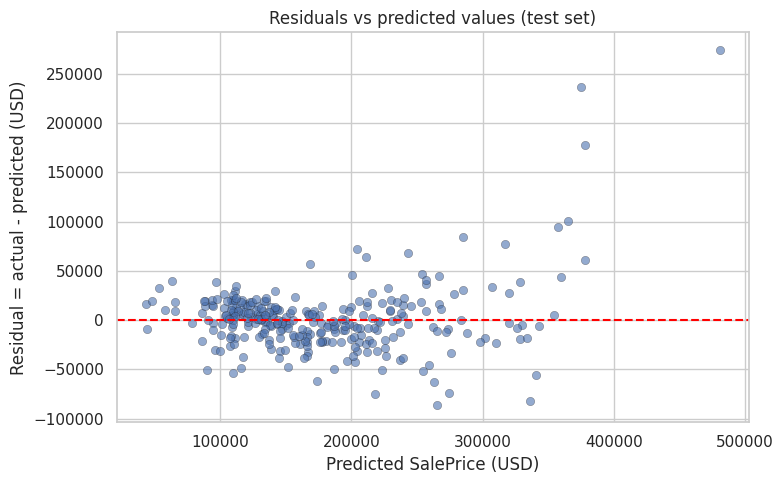

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_test, residuals_test, alpha=0.6, edgecolor="k", linewidth=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted SalePrice (USD)")
plt.ylabel("Residual = actual - predicted (USD)")
plt.title("Residuals vs predicted values (test set)")
plt.tight_layout()
plt.show()

**Interpretation.** For most houses (predicted price under ~250,000 USD), the residuals are scattered randomly around zero, which is what we'd want. But for more expensive houses, the spread gets a lot wider and the errors are mostly positive — meaning the model tends to underpredict expensive houses. So the residuals aren't fully random, which tells us a straight-line model is missing something for the pricier houses.

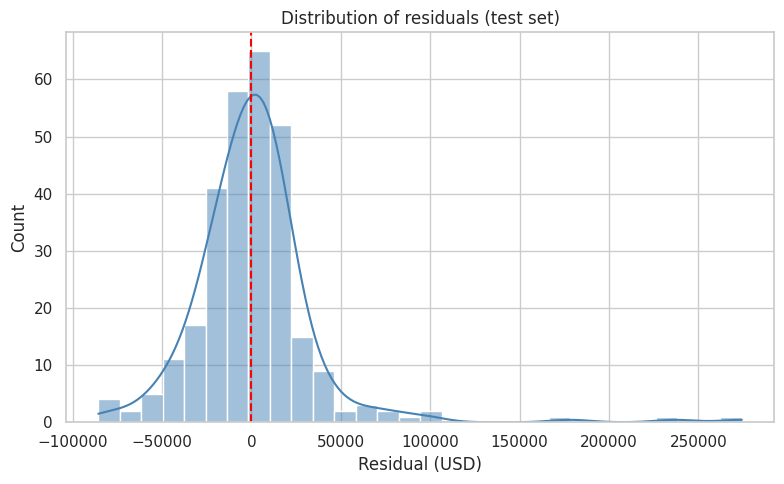

In [31]:
plt.figure(figsize=(8, 5))
sns.histplot(residuals_test, bins=30, kde=True, color="steelblue")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residual (USD)")
plt.title("Distribution of residuals (test set)")
plt.tight_layout()
plt.show()

**Interpretation.** The residuals are roughly bell-shaped and centered near zero, so most predictions aren't too far off. There's a long tail on the right though — some houses are underpredicted by up to 274,000 USD, while overpredictions only go down to about −86,000 USD. So the errors aren't quite symmetric.

In [32]:
pred_test_series = pd.Series(y_pred_test, index=y_test.index)   # predictions labelled with the same row index as y_test
worst = residuals_test.abs().sort_values(ascending=False).head(5).index
worst_table = pd.DataFrame({
    "Id": train.loc[worst, "Id"],
    "Actual (USD)": y_test[worst],
    "Predicted (USD)": pred_test_series[worst],
    "Residual (USD)": residuals_test[worst],
    "GrLivArea": train.loc[worst, "GrLivArea"],
    "OverallQual": train.loc[worst, "OverallQual"],
    "Neighborhood": train.loc[worst, "Neighborhood"],
}).reset_index(drop=True)
display(worst_table.style.hide(axis="index").format(
    {"Actual (USD)": "{:,.0f}", "Predicted (USD)": "{:,.0f}", "Residual (USD)": "{:+,.0f}", "GrLivArea": "{:,.0f}"}))

share_sq = (residuals_test[worst] ** 2).sum() / (residuals_test ** 2).sum()
print(f"These 5 houses are {5 / len(residuals_test):.1%} of the test set but account for {share_sq:.1%} of the total squared error.")

Id,Actual (USD),Predicted (USD),Residual (USD),GrLivArea,OverallQual,Neighborhood
692,"755,000","480,772","+274,228","4,316",10,NoRidge
899,"611,657","374,625","+237,032","2,364",9,NridgHt
1047,"556,581","378,396","+178,185","2,868",9,StoneBr
1244,"465,000","364,784","+100,216","2,076",10,NridgHt
592,"451,950","357,528","+94,422","2,296",10,NridgHt


These 5 houses are 1.7% of the test set but account for 50.0% of the total squared error.


**Interpretation.** The 5 worst predictions are all underpredicted, expensive houses (452,000–755,000 USD), with high quality ratings and in top neighborhoods like `NoRidge` and `NridgHt`. That's only 5 out of 292 houses, but they account for about half of the total squared error — so a handful of luxury homes are driving up the MSE/RMSE.

---
## 10. Regression Metrics

> **Task 12 (Part 5):** Compute MAE, MSE, RMSE, and R² on the test set. Report them in a small table.

We check the model on the test set using four standard regression metrics.


In [33]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

def fmt_metric(name, value, signed=False):
    sign = "+" if signed else ""
    if name == "R2":
        return f"{value:{sign}.4f}"
    if name == "MSE":
        return f"{value:{sign},.0f} (USD squared)"
    return f"{value:{sign},.0f} USD"

test_metrics = regression_metrics(y_test, y_pred_test)

metric_table = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R-squared (R2)"],
    "Test value": [fmt_metric(k, test_metrics[k]) for k in ["MAE", "MSE", "RMSE", "R2"]],
    "What it measures": ["Average size of the errors, ignoring direction (in dollars)",
                         "Average of the squared errors (punishes large errors heavily; in dollars squared)",
                         "Square root of MSE: a typical error size in dollars, sensitive to large errors",
                         "Share of the variation in price explained by the model (1 = perfect, 0 = no better than the mean)"],
})
display(metric_table.style.hide(axis="index").set_properties(subset=["What it measures"], **{"text-align": "left"}))

print(f"Average SalePrice in the test set: {y_test.mean():,.0f} USD")
print(f"MAE as a share of the average price : {100 * test_metrics['MAE'] / y_test.mean():.1f}%")
print(f"RMSE as a share of the average price: {100 * test_metrics['RMSE'] / y_test.mean():.1f}%")

Metric,Test value,What it measures
MAE,"21,413 USD","Average size of the errors, ignoring direction (in dollars)"
MSE,"1,247,410,540 (USD squared)",Average of the squared errors (punishes large errors heavily; in dollars squared)
RMSE,"35,319 USD","Square root of MSE: a typical error size in dollars, sensitive to large errors"
R-squared (R2),0.8374,"Share of the variation in price explained by the model (1 = perfect, 0 = no better than the mean)"


Average SalePrice in the test set: 178,840 USD
MAE as a share of the average price : 12.0%
RMSE as a share of the average price: 19.7%


> **Task 13 (Part 5):** In your own words, what does each metric tell you, and which one would you show to a non-technical stakeholder? Why?

**Interpretation.**

- **MAE = 21,413 USD** — on average, predictions are off by about 21,400 USD, which is about 12% of the average price.
- **MSE = 1,247,410,540 USD²** — the average squared error. Hard to read on its own since it's in dollars squared, but it's the value Linear Regression is actually minimizing.
- **RMSE = 35,319 USD** — like MAE but more sensitive to big mistakes. It's noticeably higher than MAE because of the large errors on expensive houses.
- **R² = 0.8374** — the model explains about 84% of the variation in price.

For a non-technical audience, MAE is probably the easiest metric to explain — "our estimates are usually about 21,000 USD (12%) off" makes sense without any math background. R² is a good second number to mention.

---
## 🔷 Part 6 — Training vs. Testing & Generalization
*(Lab Manual — Tasks 14–15)*

---
## 11. Training vs Testing Performance

> **Task 14 (Part 6):** Compute MAE, MSE, RMSE, and R² on the training set, and place them side by side with the Part 5 test-set metrics in one comparison table.


In [34]:
train_metrics = regression_metrics(y_train, y_pred_train)

names = ["MAE", "MSE", "RMSE", "R2"]
compare = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R-squared (R2)"],
    "Training": [fmt_metric(k, train_metrics[k]) for k in names],
    "Testing": [fmt_metric(k, test_metrics[k]) for k in names],
    "Difference (Test - Train)": [fmt_metric(k, test_metrics[k] - train_metrics[k], signed=True) for k in names],
})
display(compare.style.hide(axis="index"))

Metric,Training,Testing,Difference (Test - Train)
MAE,"20,552 USD","21,413 USD",+861 USD
MSE,"1,062,841,789 (USD squared)","1,247,410,540 (USD squared)","+184,568,752 (USD squared)"
RMSE,"32,601 USD","35,319 USD","+2,717 USD"
R-squared (R2),0.8218,0.8374,+0.0156


**Interpretation.** Errors are a bit higher on the test set (MAE 21,413 vs 20,552 USD, RMSE 35,319 vs 32,601 USD). Interestingly, R² is slightly higher on test (0.8374 vs 0.8218) — this is mostly because the test set happens to have a bit more price variation, not because the model does better on it. Overall, the differences are small.

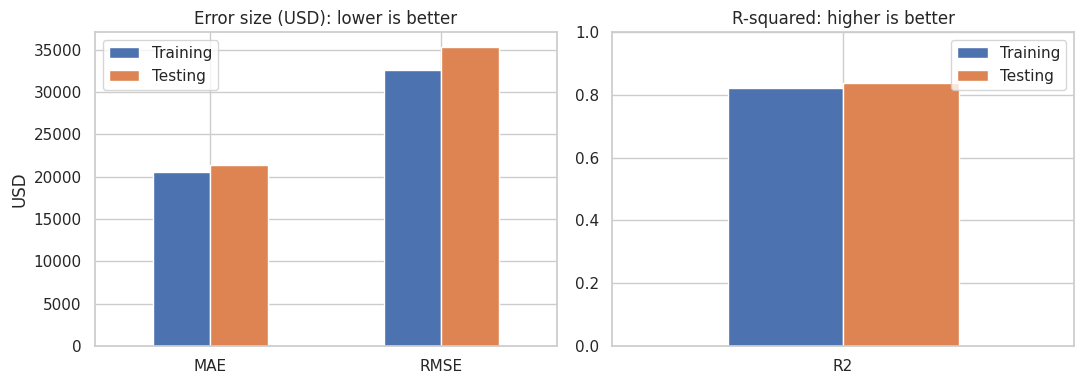

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

err = pd.DataFrame({"Training": [train_metrics["MAE"], train_metrics["RMSE"]],
                    "Testing": [test_metrics["MAE"], test_metrics["RMSE"]]}, index=["MAE", "RMSE"])
err.plot(kind="bar", ax=axes[0], color=["#4c72b0", "#dd8452"], rot=0)
axes[0].set_title("Error size (USD): lower is better")
axes[0].set_ylabel("USD")

r2 = pd.DataFrame({"Training": [train_metrics["R2"]], "Testing": [test_metrics["R2"]]}, index=["R2"])
r2.plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452"], rot=0)
axes[1].set_ylim(0, 1)
axes[1].set_title("R-squared: higher is better")

plt.tight_layout()
plt.show()

> **Task 15 (Part 6):** Is there a large gap between training and testing performance? What would a large gap suggest about overfitting or generalization, and what does the actual result suggest here?

**Interpretation.** MAE, RMSE and R² are all pretty close between training and testing. There is no large difference between the training and testing performance, so there is no strong sign of overfitting — the model isn't just memorizing the training houses. Both scores are only moderate rather than excellent, though, which suggests the bigger issue is that a straight-line model can't fully capture how price actually depends on these features, rather than the model being overfit.

---
## 🔷 Part 7 — Final Model Analysis, Conclusion & Kaggle Submission
*(Lab Manual — Tasks 16–19)*

---
## 12. Model Interpretation

> **Task 16 (Part 7):** Looking back at the Part 4 coefficient table, which 2–3 features appear most influential on price? Justify using coefficient magnitudes (a larger coefficient does not automatically mean a more important feature if scales differ).

### 12.1 Which features are the most influential?

A bigger coefficient doesn't always mean a bigger effect, since features are measured in different units (square feet vs. quality points vs. years). To compare them fairly, we multiply each coefficient by how much that feature typically varies (its standard deviation) to get a comparable "typical effect" in dollars.


In [36]:
plain_features = NUM_FEATURES + ["KitchenQual", "CentralAir"]   # dummy columns are compared with a baseline, so shown separately
coef_series = pd.Series(model.coef_, index=X_train.columns)

influence = pd.DataFrame({
    "Feature": plain_features,
    "Raw coefficient": coef_series[plain_features].values,
    "Std. dev. of feature": X_train[plain_features].std().values,
})
influence["Price change for +1 std. dev. (USD)"] = influence["Raw coefficient"] * influence["Std. dev. of feature"]
influence["Rank by raw coefficient"] = influence["Raw coefficient"].abs().rank(ascending=False).astype(int)
influence["Rank by +1 std. dev. effect"] = influence["Price change for +1 std. dev. (USD)"].abs().rank(ascending=False).astype(int)
influence = influence.sort_values("Rank by +1 std. dev. effect").reset_index(drop=True)

display(influence.style.hide(axis="index").format({
    "Raw coefficient": "{:,.2f}", "Std. dev. of feature": "{:,.2f}", "Price change for +1 std. dev. (USD)": "{:+,.0f}"}))

Feature,Raw coefficient,Std. dev. of feature,Price change for +1 std. dev. (USD),Rank by raw coefficient,Rank by +1 std. dev. effect
GrLivArea,54.13,524.43,"+28,389",8,1
OverallQual,"13,415.37",1.37,"+18,347",2,2
KitchenQual,"14,532.94",0.66,"+9,607",1,3
GarageCars,"10,187.11",0.74,"+7,540",3,4
YearBuilt,233.28,30.68,"+7,156",7,5
LotArea,0.53,"10,759.37","+5,729",10,6
Fireplaces,"6,407.88",0.65,"+4,134",4,7
TotalBsmtSF,4.23,440.68,"+1,865",9,8
CentralAir,"5,651.62",0.26,"+1,453",5,9
FullBath,"-1,556.94",0.55,-852,6,10


**Interpretation.** By raw coefficient, `KitchenQual` (14,533) and `OverallQual` (13,415) look like the top features, while `GrLivArea` (54) looks tiny — but that's just because `GrLivArea` is measured in square feet. Once we adjust for typical variation, `GrLivArea` is actually the strongest feature (+28,389 USD for a typical increase), followed by `OverallQual` (+18,347 USD) and `KitchenQual` (+9,607 USD). `FullBath` still comes out slightly negative (−852 USD), for the reason explained in Section 8.

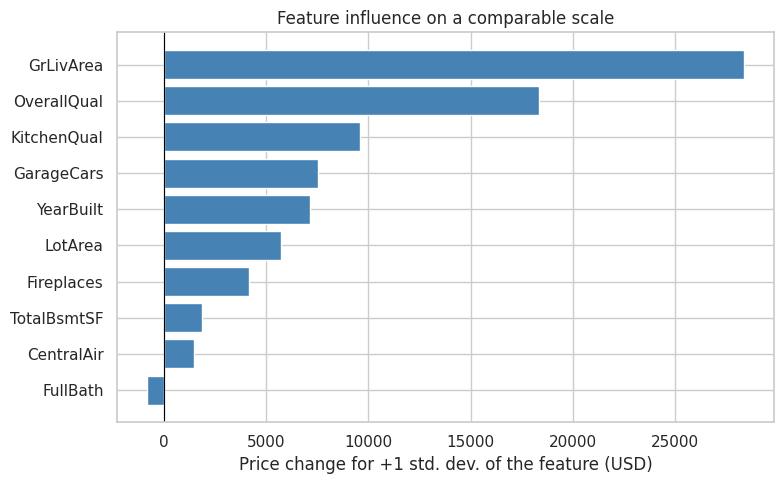

In [37]:
plt.figure(figsize=(8, 5))
order = influence.sort_values("Price change for +1 std. dev. (USD)")
plt.barh(order["Feature"], order["Price change for +1 std. dev. (USD)"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Price change for +1 std. dev. of the feature (USD)")
plt.title("Feature influence on a comparable scale")
plt.tight_layout()
plt.show()

**Interpretation.** The chart confirms `GrLivArea` and `OverallQual` are the two biggest drivers of price. `KitchenQual`, `GarageCars`, `YearBuilt` and `LotArea` matter a moderate amount, and `Fireplaces`, `TotalBsmtSF` and `CentralAir` matter less. `Neighborhood` also has a big impact (e.g. `NoRidge` adds about +75,000 USD), but since it's spread across many dummy columns it doesn't show up as one single bar here.

### 12.2 What the model, residuals, and train/test comparison tell us

- **Feature effects.** Bigger, higher-quality, newer houses with more garage space sell for more. Neighborhood alone can shift the price by up to ~70,000 USD.
- **Intercept.** About −562,090 USD, with no real-world meaning since "all features = 0" isn't a real house.
- **Performance.** On the test set: R² = 0.8374, MAE = 21,413 USD, RMSE = 35,319 USD — solid for a simple 12-feature linear model.
- **Residuals.** Mostly random and centered near zero for typical houses, but the model consistently underpredicts expensive houses, and just 5 houses cause about half the squared error.
- **Train vs test.** Very similar scores on both sets (R² around 0.82–0.84), so there's no strong sign of overfitting — the model's limits come more from being a straight line than from memorizing training data.
- **Limitations.** Linear Regression assumes straight-line effects, is sensitive to outliers, and gets a bit unstable when features overlap (like `FullBath` and `GrLivArea`). It also can't capture the extra premium on luxury homes, and could technically predict a negative price for a very small/cheap house.

---
## 13. Conclusion

> **Task 18 (Part 7):** Apply the same feature selection and encoding used on train.csv to test.csv, predict SalePrice for every row, and build a submission.csv file with exactly two columns: Id and SalePrice.

### 13.1 Kaggle submission file (`submission.csv`)

We apply the same feature selection and encoding to `test.csv`, predict `SalePrice` for every test house, and save a two-column file (`Id`, `SalePrice`) matching `sample_submission.csv`'s format.


In [38]:
# 1) Same feature selection and encoding as the training data, columns aligned to the training columns
X_kaggle = encode_features(test).reindex(columns=X_train.columns, fill_value=0)

# 2) test.csv has a few missing values in the chosen features (see Section 2.9).
#    Fill them with the median of the TRAINING features only (no information from test.csv is used).
still_missing = X_kaggle.isna().sum()
still_missing = still_missing[still_missing > 0]
fill_table = pd.DataFrame({
    "Missing values in test": still_missing,
    "Filled with (training median)": X_train.median()[still_missing.index],
})
display(fill_table)

X_kaggle = X_kaggle.fillna(X_train.median())
assert X_kaggle.isna().sum().sum() == 0
assert list(X_kaggle.columns) == list(X_train.columns)
print(f"Kaggle feature matrix: {X_kaggle.shape}  (same columns as the training features)")

,Missing values in test,Filled with (training median)
TotalBsmtSF,1,997.50
GarageCars,1,2.00
KitchenQual,1,3.00


Kaggle feature matrix: (1459, 41)  (same columns as the training features)


**Interpretation.** `test.csv` has 3 missing values in our chosen features (one each in `TotalBsmtSF`, `GarageCars`, `KitchenQual`), matching what we found in Section 2.10. We fill these using the training set's median values, so no information from `test.csv` leaks in. The final feature matrix has 1,459 rows and the same 41 columns as the training data.

In [39]:
# 3) Predict, making sure every prediction is a valid positive price (Kaggle scores in log space)
kaggle_pred = model.predict(X_kaggle)
n_nonpositive = int((kaggle_pred <= 0).sum())
print(f"Predictions that were zero or negative: {n_nonpositive}")
if n_nonpositive > 0:
    kaggle_pred = np.clip(kaggle_pred, y_train.min(), None)   # safety net; not needed when the count above is 0

# 4) Build and save the submission (index=False -> no extra index column)
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": kaggle_pred})
submission.to_csv("submission.csv", index=False)
print("Saved: submission.csv  (in Colab it is in /content - see the Files panel on the left)")

Predictions that were zero or negative: 0
Saved: submission.csv  (in Colab it is in /content - see the Files panel on the left)


**Interpretation.** None of the predictions came out zero or negative, so no fixing was needed. `submission.csv` was saved with `index=False`, so it only has the two required columns.

In [40]:
# 5) Re-read the SAVED file and validate it against sample_submission.csv
saved = pd.read_csv("submission.csv")
display(saved.head())
print("Shape of submission.csv:", saved.shape)
print("Shape of sample_submission.csv:", sample_sub.shape)

,Id,SalePrice
0,1461,"109,986.35"
1,1462,"163,974.71"
2,1463,"161,279.96"
3,1464,"186,048.61"
4,1465,"255,430.23"


Shape of submission.csv: (1459, 2)
Shape of sample_submission.csv: (1459, 2)


**Interpretation.** The saved file has 1,459 rows and 2 columns, matching `sample_submission.csv`. The first few predictions look reasonable (e.g. about 109,986 USD for house 1461).

In [41]:
checks = pd.DataFrame({
    "Check": ["Column names are exactly ['Id', 'SalePrice']",
              "Row count equals sample_submission.csv",
              "Id values match sample_submission.csv (same order)",
              "Id values are unique",
              "No missing predictions",
              "All predictions are positive",
              "No accidental index column"],
    "Passed": [list(saved.columns) == ["Id", "SalePrice"] == list(sample_sub.columns),
               len(saved) == len(sample_sub),
               saved["Id"].equals(sample_sub["Id"]),
               bool(saved["Id"].is_unique),
               bool(saved["SalePrice"].notna().all()),
               bool((saved["SalePrice"] > 0).all()),
               not any(str(c).startswith("Unnamed") for c in saved.columns)],
})
display(checks)
assert checks["Passed"].all(), "Submission validation failed - do not upload this file"
print("All submission checks passed.")

# Optional: download submission.csv to your computer (works in Colab only)
try:
    from google.colab import files
    files.download("submission.csv")
except Exception:
    pass

,Check,Passed
0,"Column names are exactly ['Id', 'SalePrice']",True
1,Row count equals sample_submission.csv,True
2,Id values match sample_submission.csv (same order),True
3,Id values are unique,True
4,No missing predictions,True
5,All predictions are positive,True
6,No accidental index column,True


All submission checks passed.


**Interpretation.** All 7 checks pass — correct column names, correct row count, matching `Id` order, no duplicates, no missing or negative predictions, and no extra index column. The file is valid to upload to Kaggle.

In [42]:
# Local estimate of the Kaggle metric (RMSE between log prices) using the held-out 20% of train.csv
local_rmsle = np.sqrt(mean_squared_error(np.log(y_test), np.log(np.clip(y_pred_test, 1, None))))
print(f"Local RMSE on log prices (held-out test split): {local_rmsle:.4f}")

Local RMSE on log prices (held-out test split): 0.1692


**Interpretation.** Kaggle scores using RMSE on log(price). On our own held-out test set, that comes out to about 0.1692. The actual leaderboard score might be a little different since it's scored on a different set of houses.

### 13.2 Final interpretation

> **Task 17 (Part 7):** Write a short final interpretation (5–7 sentences): How well does the model predict house prices? Which metric is most useful and why? Which feature has the strongest effect? What limitations does Linear Regression have? What would you try next?

Overall, the model does a reasonable job predicting house prices — it explains about 84% of the price variation (R² = 0.8374) and is typically about 21,400 USD (12%) off. MAE is probably the best metric to report to someone non-technical, since it's easy to understand and isn't skewed by a few extreme cases. `GrLivArea` (living area) has the strongest effect on price, followed by `OverallQual`. The main limitations are that Linear Regression assumes straight-line effects (so it underpredicts expensive houses), some features overlap with each other which makes individual coefficients harder to trust, and we only used 12 of the 79 available features. If I did this again, I'd try predicting `log(SalePrice)` instead (since that's what Kaggle actually scores on), and maybe try a tree-based model to see if it captures the pricing patterns better.

### 13.3 Conclusion summary

- **Problem:** predict house sale prices in Ames, Iowa using Multiple Linear Regression.
- **Dataset:** Kaggle *House Prices — Advanced Regression Techniques* (1,460 labeled houses in `train.csv`, 1,459 unlabeled in `test.csv`).
- **Target:** `SalePrice` (USD).
- **Features (12):** `GrLivArea`, `LotArea`, `OverallQual`, `YearBuilt`, `TotalBsmtSF`, `GarageCars`, `FullBath`, `Fireplaces` (numerical); `Neighborhood`, `HouseStyle`, `KitchenQual`, `CentralAir` (categorical).
- **Preprocessing:** `CentralAir` → 0/1, `KitchenQual` → ordinal 1–5, `Neighborhood`/`HouseStyle` → one-hot with `drop_first=True` (41 columns total); 3 missing test values filled with training medians; 80/20 train/test split.
- **Model:** scikit-learn `LinearRegression`, trained on 1,168 houses, tested on 292.
- **Test set results:** MAE = 21,413 USD, MSE = 1,247,410,540 USD², RMSE = 35,319 USD, R² = 0.8374. Training R² = 0.8218 — close to the test score, so no strong sign of overfitting.
- **Kaggle submission:** `submission.csv` generated and validated (1,459 rows, columns `Id`/`SalePrice`, no missing values).


### 13.4 Kaggle leaderboard result

> **Task 19 (Part 7):** Submit submission.csv on the competition's "Submit Predictions" page. Record the public leaderboard score and rank, and reflect on seeing the model measured against thousands of other real submissions.

**Public Kaggle Leaderboard Score:** 0.16989

**Public Kaggle Leaderboard Rank:** 2977

**Reflection:** It was interesting to see my model evaluated against thousands of real submissions on Kaggle. The leaderboard result helped me understand how a simple Linear Regression model performs in a real machine learning competition.
